In [1]:
# библиотеки и параметры, общие для обеих задач
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
METRICS = {"classification": ["F1_macro", "Accuracy"], "regression": ["MAE", "RMSE", "R2"]}
PRIMARY = {"classification": "F1_macro", "regression": "MAE"}
VARIANTS = ["dummy", "sklearn", "sklearn+", "own", "own+"]

In [2]:
# читаем исходные таблицы из архивов UCI и явно отделяем цели от признаков
def read_uci_file(archive_name, filename, **read_options):
    url = f"https://archive.ics.uci.edu/static/public/{archive_name}"
    with urlopen(url, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        member = next(name for name in archive.namelist() if Path(name).name == filename)
        with archive.open(member) as source:
            return pd.read_csv(source, header=None, **read_options)


wifi_columns = [f"signal_{i}" for i in range(1, 8)] + ["room"]
wifi = read_uci_file(
    "422/wireless+indoor+localization.zip", "wifi_localization.txt",
    sep=r"\s+", names=wifi_columns,
)

hardware_features = ["MYCT", "MMIN", "MMAX", "CACH", "CHMIN", "CHMAX"]
hardware_columns = ["vendor", "model", *hardware_features, "PRP", "ERP"]
hardware = read_uci_file(
    "29/computer+hardware.zip", "machine.data", names=hardware_columns,
)

assert wifi.shape == (2000, 8) and hardware.shape == (209, 10)
assert set(wifi["room"]) == {1, 2, 3, 4}
assert not wifi.isna().any().any() and not hardware.isna().any().any()

DATA = {
    "classification": (wifi[wifi_columns[:-1]].to_numpy(dtype=float), wifi["room"].to_numpy()),
    "regression": (hardware[hardware_features].to_numpy(dtype=float), hardware["PRP"].to_numpy(dtype=float)),
}
for task, (X, y) in DATA.items():
    print(f"{TASK_NAMES[task]}: {X.shape[0]} объектов, {X.shape[1]} признаков")

Классификация: 2000 объектов, 7 признаков
Регрессия: 209 объектов, 6 признаков


In [3]:
# преобразуем признаки внутри каждого разбиения и считаем метрики
def transform_features(X_train, X_eval, preparation):
    if preparation == "polynomial":
        transformer = make_pipeline(
            StandardScaler(),
            PolynomialFeatures(degree=2, include_bias=False),
            StandardScaler(),
        )
        return transformer.fit_transform(X_train), transformer.transform(X_eval)
    if preparation == "relative":
        X_train = np.column_stack([X_train, X_train - X_train.max(axis=1, keepdims=True)])
        X_eval = np.column_stack([X_eval, X_eval - X_eval.max(axis=1, keepdims=True)])
    elif preparation == "ratios":
        def with_ratios(X):
            memory_growth = X[:, 2] / np.maximum(X[:, 1], 1)
            cache_share = X[:, 3] / np.maximum(X[:, 2], 1)
            return np.column_stack([X, memory_growth, cache_share])

        X_train, X_eval = with_ratios(X_train), with_ratios(X_eval)
    elif preparation == "log":
        X_train, X_eval = np.log1p(X_train), np.log1p(X_eval)

    if preparation in {"scale", "log", "relative"}:
        scaler = StandardScaler().fit(X_train)
        X_train, X_eval = scaler.transform(X_train), scaler.transform(X_eval)
    return X_train, X_eval


def folds(task, X, y, n_splits, seed):
    splitter_class = StratifiedKFold if task == "classification" else KFold
    return splitter_class(n_splits=n_splits, shuffle=True, random_state=seed).split(X, y)


def predict_on(model, preparation, X_train, y_train, X_eval):
    X_train, X_eval = transform_features(X_train, X_eval, preparation)
    return model.fit(X_train, y_train).predict(X_eval)


def scores(task, y, prediction):
    if task == "classification":
        return {
            "F1_macro": f1_score(y, prediction, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, prediction),
        }
    return {
        "MAE": mean_absolute_error(y, prediction),
        "RMSE": np.sqrt(mean_squared_error(y, prediction)),
        "R2": r2_score(y, prediction),
    }

## Модели

Для четырёх комнат используем softmax с ускоренным градиентным спуском и проверкой сходимости.
Для PRP проверяем исходные признаки, их преобразования и квадратичные признаки с L2-регуляризацией (Ridge)

In [4]:
# линейную регрессию решаем через МНК, логистическую - ускоренным градиентным спуском
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge


def with_intercept(X):
    return np.column_stack([np.ones(len(X)), X])


class LeastSquares:
    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        design = with_intercept(X)
        if self.alpha > 0:
            penalty = np.eye(design.shape[1])
            penalty[0, 0] = 0
            design = np.vstack([design, np.sqrt(self.alpha) * penalty])
            y = np.concatenate([y, np.zeros(penalty.shape[0])])
        self.coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
        return self

    def predict(self, X):
        return with_intercept(X) @ self.coefficients


class SoftmaxRegression:
    def __init__(self, C=1.0, iterations=10000, tolerance=1e-6):
        self.C = C
        self.iterations = iterations
        self.tolerance = tolerance

    @staticmethod
    def gradient(design, labels, weights, penalty):
        logits = design @ weights
        probabilities = np.exp(logits - logits.max(axis=1, keepdims=True))
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        gradient = design.T @ (probabilities - labels) / len(design)
        gradient[1:] += penalty * weights[1:]
        return gradient

    def fit(self, X, y):
        design = with_intercept(X)
        self.classes, encoded = np.unique(y, return_inverse=True)
        labels = np.eye(len(self.classes))[encoded]
        penalty = 1.0 / (self.C * len(X))
        step = 1.0 / (0.5 * np.linalg.norm(design, ord=2) ** 2 / len(X) + penalty)
        weights = np.zeros((design.shape[1], len(self.classes)))
        lookahead = weights.copy()
        momentum = 1.0

        for iteration in range(1, self.iterations + 1):
            gradient = self.gradient(design, labels, lookahead, penalty)
            if np.max(np.abs(gradient)) < self.tolerance:
                weights = lookahead
                break
            next_weights = lookahead - step * gradient
            next_momentum = (1 + np.sqrt(1 + 4 * momentum ** 2)) / 2
            lookahead = next_weights + (momentum - 1) / next_momentum * (next_weights - weights)
            weights, momentum = next_weights, next_momentum

        self.weights = weights
        self.n_iter_ = iteration
        self.gradient_norm_ = float(np.max(np.abs(self.gradient(design, labels, weights, penalty))))
        self.converged_ = self.gradient_norm_ < self.tolerance
        return self

    def predict(self, X):
        return self.classes[(with_intercept(X) @ self.weights).argmax(axis=1)]


def library_model(task, C=1.0, alpha=0.0):
    if task == "classification":
        return LogisticRegression(C=C, max_iter=2000, tol=1e-6)
    return Ridge(alpha=alpha) if alpha > 0 else LinearRegression()


def own_model(task, C=1.0, alpha=0.0):
    return SoftmaxRegression(C=C) if task == "classification" else LeastSquares(alpha=alpha)

In [5]:
# проверяем регуляризацию, преобразования входов и квадратичные признаки
LAB = 2
CONFIGS = {
    "classification": {
        "base": ("scale", {"C": 1.0}),
        "stronger_regularization": ("scale", {"C": 0.1}),
        "weaker_regularization": ("scale", {"C": 10.0}),
        "relative": ("relative", {"C": 1.0}),
        "relative_weaker_regularization": ("relative", {"C": 10.0}),
    },
    "regression": {
        "base": ("raw", {}),
        "log": ("log", {}),
        "ratios": ("ratios", {}),
        "ridge": ("scale", {"alpha": 10.0}),
        "polynomial_ridge_1": ("polynomial", {"alpha": 1.0}),
        "polynomial_ridge_10": ("polynomial", {"alpha": 10.0}),
        "polynomial_ridge_100": ("polynomial", {"alpha": 100.0}),
    },
}

## Эксперимент

Сравниваем Dummy, исходные модели (sklearn и own) и модели с настройками, выбранными на внутренних фолдах (sklearn+ и own+).
Положительное Delta означает улучшение. Таблица сходимости показывает, достигла ли своя логистическая регрессия заданной точности на каждом внешнем фолде

In [6]:
# на каждом внешнем фолде выбираем настройки только по внутренней кросс-валидации
def choose_candidate(task, X_train, y_train, seed):
    variants = CONFIGS[task]
    inner_folds = list(folds(task, X_train, y_train, n_splits=3, seed=seed))
    means = {}
    for name, (preparation, params) in variants.items():
        values = []
        for train, valid in inner_folds:
            prediction = predict_on(
                library_model(task, **params), preparation,
                X_train[train], y_train[train], X_train[valid],
            )
            values.append(scores(task, y_train[valid], prediction)[PRIMARY[task]])
        means[name] = float(np.mean(values))
    select_best = max if task == "classification" else min
    return select_best(means, key=means.get), means


def run_experiments():
    rows, search_rows, diagnostics = [], [], []
    for task, (X, y) in DATA.items():
        for fold, (train, test) in enumerate(folds(task, X, y, n_splits=5, seed=SEED), start=1):
            X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]
            selected, means = choose_candidate(task, X_train, y_train, SEED + fold)
            search_rows.extend(
                {"task": task, "fold": fold, "candidate": name, "score": score, "selected": name == selected}
                for name, score in means.items()
            )

            baseline_prep, baseline_params = CONFIGS[task]["base"]
            selected_prep, selected_params = CONFIGS[task][selected]
            dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
            experiments = {
                "dummy": (dummy, "raw"),
                "sklearn": (library_model(task, **baseline_params), baseline_prep),
                "sklearn+": (library_model(task, **selected_params), selected_prep),
                "own": (own_model(task, **baseline_params), baseline_prep),
                "own+": (own_model(task, **selected_params), selected_prep),
            }
            for variant, (model, preparation) in experiments.items():
                prediction = predict_on(model, preparation, X_train, y_train, X_test)
                metrics = scores(task, y_test, prediction)
                if task == "classification" and variant.startswith("own"):
                    diagnostics.append({
                        "fold": fold, "variant": variant, "iterations": model.n_iter_,
                        "max_gradient": model.gradient_norm_, "converged": model.converged_,
                    })
                rows.append({"lab": LAB, "task": task, "fold": fold, "variant": variant,
                             "candidate": selected if variant.endswith("+") else "base", **metrics})
            print(f"{TASK_NAMES[task]} - фолд {fold}/5 - настройки {selected}", flush=True)
    return pd.DataFrame(rows), pd.DataFrame(search_rows), pd.DataFrame(diagnostics)

In [7]:
# запускаем эксперимент, показываем результаты гипотез и сохраняем оценки по фолдам
results, search, convergence = run_experiments()
for task in TASK_NAMES:
    print(f"\n{TASK_NAMES[task]} - внутренний поиск по {PRIMARY[task]}")
    selection = search.loc[search["task"] == task].groupby("candidate").agg(
        cv_mean=("score", "mean"), cv_std=("score", "std"), selected_folds=("selected", "sum"),
    )
    display(selection.sort_values("cv_mean", ascending=task == "regression").round(4))

    print("Внешняя кросс-валидация - среднее и стандартное отклонение")
    report = results.loc[results["task"] == task].groupby("variant")[METRICS[task]].agg(["mean", "std"])
    display(report.reindex(VARIANTS).round(4))

print("\nСходимость своей логистической регрессии")
display(convergence)
if not convergence["converged"].all():
    print("В некоторых фолдах достигнут лимит итераций, требуется проверить сходимость")

output = Path("results") / f"lab_{LAB:02d}.csv"
output.parent.mkdir(exist_ok=True)
results.to_csv(output, index=False)
print(f"Файл для итогового сравнения: {output}")

Классификация - фолд 1/5 - настройки relative
Классификация - фолд 2/5 - настройки relative
Классификация - фолд 3/5 - настройки relative
Классификация - фолд 4/5 - настройки relative
Классификация - фолд 5/5 - настройки relative
Регрессия - фолд 1/5 - настройки polynomial_ridge_10
Регрессия - фолд 2/5 - настройки polynomial_ridge_10
Регрессия - фолд 3/5 - настройки polynomial_ridge_10
Регрессия - фолд 4/5 - настройки polynomial_ridge_10
Регрессия - фолд 5/5 - настройки polynomial_ridge_10

Классификация - внутренний поиск по F1_macro


,cv_mean,cv_std,selected_folds
candidate,,,
relative,0.9814,0.0030,5
relative_weaker_regularization,0.9808,0.0033,0
weaker_regularization,0.9805,0.0026,0
base,0.9790,0.0020,0
stronger_regularization,0.9733,0.0039,0


Внешняя кросс-валидация - среднее и стандартное отклонение


F1_macro         Accuracy        
             mean     std     mean     std
variant                                   
dummy       0.100  0.0000    0.250  0.0000
sklearn     0.979  0.0072    0.979  0.0072
sklearn+    0.979  0.0066    0.979  0.0065
own         0.979  0.0072    0.979  0.0072
own+        0.979  0.0066    0.979  0.0065


Регрессия - внутренний поиск по MAE


,cv_mean,cv_std,selected_folds
candidate,,,
polynomial_ridge_10,33.9428,2.1105,5
polynomial_ridge_100,38.1765,2.0397,0
polynomial_ridge_1,42.1162,4.2452,0
ridge,43.0516,2.9523,0
base,44.8022,3.2239,0
ratios,45.0010,2.9150,0
log,73.8331,9.8283,0


Внешняя кросс-валидация - среднее и стандартное отклонение


MAE               RMSE               R2        
             mean      std      mean      std    mean     std
variant                                                      
dummy     78.3256  21.2535  160.4872  63.1679 -0.1438  0.0294
sklearn   41.0904   7.5210   65.6898  22.4836  0.7848  0.1080
sklearn+  28.4417   7.4717   51.3235  21.2558  0.8531  0.1447
own       41.0904   7.5210   65.6898  22.4836  0.7848  0.1080
own+      28.4417   7.4717   51.3235  21.2558  0.8531  0.1447


Сходимость своей логистической регрессии


,fold,variant,iterations,max_gradient,converged
0,1,own,2063,9.863716e-07,True
1,1,own+,2774,9.384971e-07,True
2,2,own,2295,9.668371e-07,True
3,2,own+,2823,9.928327e-07,True
4,3,own,2241,9.930575e-07,True
5,3,own+,2308,9.898831e-07,True
6,4,own,1948,9.986107e-07,True
7,4,own+,2677,9.323538e-07,True
8,5,own,2440,9.865291e-07,True
9,5,own+,2639,9.582595e-07,True


Файл для итогового сравнения: results/lab_02.csv



Классификация - F1_macro
Эффект подбора sklearn: ухудшение, Delta=-0.0000, выигрышей 2/5, проигрышей 3/5
Своя реализация против исходной sklearn: без изменений, Delta=+0.0000, выигрышей 0/5, проигрышей 0/5
Своя реализация против настроенной sklearn: без изменений, Delta=+0.0000, выигрышей 0/5, проигрышей 0/5
Эффект переноса настроек на свою реализацию: ухудшение, Delta=-0.0000, выигрышей 2/5, проигрышей 3/5


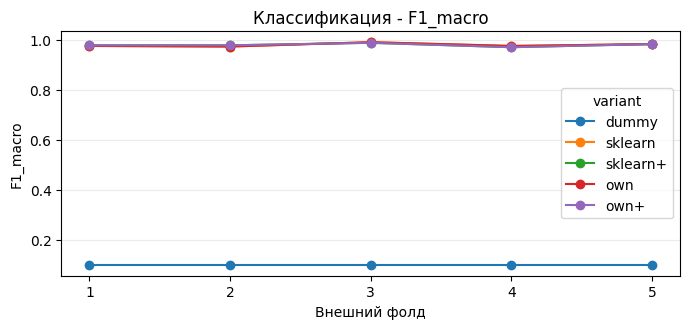


Регрессия - MAE
Эффект подбора sklearn: улучшение, Delta=+12.6487, выигрышей 5/5, проигрышей 0/5
Своя реализация против исходной sklearn: без изменений, Delta=-0.0000, выигрышей 0/5, проигрышей 0/5
Своя реализация против настроенной sklearn: без изменений, Delta=-0.0000, выигрышей 0/5, проигрышей 0/5
Эффект переноса настроек на свою реализацию: улучшение, Delta=+12.6487, выигрышей 5/5, проигрышей 0/5


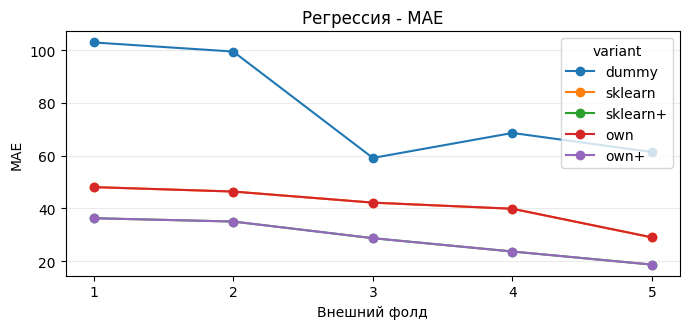

In [8]:
# считаем парные изменения метрики, чтобы сформулировать выводы по обеим задачам
comparisons = [
    ("sklearn+", "sklearn", "Эффект подбора sklearn"),
    ("own", "sklearn", "Своя реализация против исходной sklearn"),
    ("own+", "sklearn+", "Своя реализация против настроенной sklearn"),
    ("own+", "own", "Эффект переноса настроек на свою реализацию"),
]
for task in TASK_NAMES:
    metric = PRIMARY[task]
    values = results.loc[results["task"] == task].pivot(index="fold", columns="variant", values=metric)
    direction = 1 if task == "classification" else -1
    print(f"\n{TASK_NAMES[task]} - {metric}")
    for first, second, label in comparisons:
        gain = direction * (values[first] - values[second])
        mean = gain.mean()
        tendency = "улучшение" if mean > 1e-10 else "ухудшение" if mean < -1e-10 else "без изменений"
        wins = int((gain > 1e-10).sum())
        losses = int((gain < -1e-10).sum())
        print(f"{label}: {tendency}, Delta={mean:+.4f}, выигрышей {wins}/5, проигрышей {losses}/5")

    ax = values[VARIANTS].plot(marker="o", figsize=(7, 3.4), title=f"{TASK_NAMES[task]} - {metric}")
    ax.set(xlabel="Внешний фолд", ylabel=metric, xticks=values.index)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()